# Abalone Dataset: EDA and Preprocessing

The target for this data set is `Rings`

## 1. Imports and configuration

Import any missing libraries accordingly to have code run, have the abalone.data file in the same folder

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = Path("data/abalone.data")  # change this if the file is elsewhere
RANDOM_STATE = 42

FEATURE_NAMES = [
    "Sex", "Length", "Diameter", "Height", "Whole weight",
    "Shucked weight", "Viscera weight", "Shell weight", "Rings"
]
TARGET = "Rings"
CATEGORICAL_FEATURES = ["Sex"]
NUMERIC_COLUMNS = [c for c in FEATURE_NAMES if c not in CATEGORICAL_FEATURES]
PREDICTOR_NUMERIC = [c for c in NUMERIC_COLUMNS if c != TARGET]


## 2. Load and validate the data

The original UCI file has no header row and uses comma-separated values. It contains 9 columns: `Sex` as a category, seven physical measurements, and `Rings`. Below are checks for missing values along with a numerical check

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Put abalone.data beside this notebook "
        "or update DATA_PATH to the correct location."
    )

df = pd.read_csv(DATA_PATH, header=None, names=FEATURE_NAMES, skipinitialspace=True)

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())
display(df.dtypes.to_frame("dtype"))

Rows: 4,177 | Columns: 9


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


,dtype
Sex,str
Length,float64
Diameter,float64
Height,float64
Whole weight,float64
Shucked weight,float64
Viscera weight,float64
Shell weight,float64
Rings,int64


In [ ]:
# Converts expected numeric columns explicitly; malformed values become NaN and are reported below.
for col in NUMERIC_COLUMNS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values by column:")
display(df.isna().sum().rename("missing_count").to_frame())

print(f"Exact duplicate rows: {df.duplicated().sum():,}")

print("\nSex category counts:")
display(df["Sex"].value_counts(dropna=False).to_frame("count"))

print("\nNumeric value checks:")
validation = pd.DataFrame({
    "min": df[NUMERIC_COLUMNS].min(),
    "max": df[NUMERIC_COLUMNS].max(),
    "zero_count": (df[NUMERIC_COLUMNS] == 0).sum(),
    "negative_count": (df[NUMERIC_COLUMNS] < 0).sum(),
    "missing_count": df[NUMERIC_COLUMNS].isna().sum()
})
display(validation)

df.loc[
    (df["Height"] == 0) | (df["Height"] == 1.13)
      ]

Missing values by column:


,missing_count
Sex,0
Length,0
Diameter,0
Height,0
Whole weight,0
Shucked weight,0
Viscera weight,0
Shell weight,0
Rings,0


Exact duplicate rows: 0

Sex category counts:


,count
Sex,
M,1528
I,1342
F,1307



Numeric value checks:


,min,max,zero_count,negative_count,missing_count
Length,0.0750,0.8150,0,0,0
Diameter,0.0550,0.6500,0,0,0
Height,0.0000,1.1300,2,0,0
Whole weight,0.0020,2.8255,0,0,0
Shucked weight,0.0010,1.4880,0,0,0
Viscera weight,0.0005,0.7600,0,0,0
Shell weight,0.0015,1.0050,0,0,0
Rings,1.0000,29.0000,0,0,0


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.340,0.00,0.428,0.2065,0.0860,0.1150,8
2051,F,0.455,0.355,1.13,0.594,0.3320,0.1160,0.1335,8
3996,I,0.315,0.230,0.00,0.134,0.0575,0.0285,0.3505,6


### Data-quality notes

- Physical dimensions and weights should not be negative. A zero height and maximum of 1.13 is suspicious, seen in row 1258, 2052, and 3997 (in raw data set)
- `Rings` is a discrete count. It is the equivalent to determining age, common rough age estimates fall in `Rings + 1.5` years, but `Rings` target is recorded directly here.
- Exact duplicate rows are reported, fortunately there are none

## 3. Summary statistics: mean, median, standard deviation, and skewness

In [4]:
summary = df[NUMERIC_COLUMNS].agg(["count", "mean", "median", "std", "min", "max"]).T
summary["skewness"] = df[NUMERIC_COLUMNS].skew()
summary["kurtosis"] = df[NUMERIC_COLUMNS].kurtosis()
display(summary.sort_index())


,count,mean,median,std,min,max,skewness,kurtosis
Diameter,4177.0,0.407881,0.4250,0.099240,0.0550,0.6500,-0.609198,-0.045476
Height,4177.0,0.139516,0.1400,0.041827,0.0000,1.1300,3.128817,76.025509
Length,4177.0,0.523992,0.5450,0.120093,0.0750,0.8150,-0.639873,0.064621
Rings,4177.0,9.933684,9.0000,3.224169,1.0000,29.0000,1.114102,2.330687
Shell weight,4177.0,0.238831,0.2340,0.139203,0.0015,1.0050,0.620927,0.531926
Shucked weight,4177.0,0.359367,0.3360,0.221963,0.0010,1.4880,0.719098,0.595124
Viscera weight,4177.0,0.180594,0.1710,0.109614,0.0005,0.7600,0.591852,0.084012
Whole weight,4177.0,0.828742,0.7995,0.490389,0.0020,2.8255,0.530959,-0.023644


### Important Findings
- Height has skewness of 3.13 and kurtosis of 76.03
- Potentially caused by max of 1.13
- Rings is right-skewed, with mean of 9.93, median of 9, and max of 29

## 4. Feature distributions

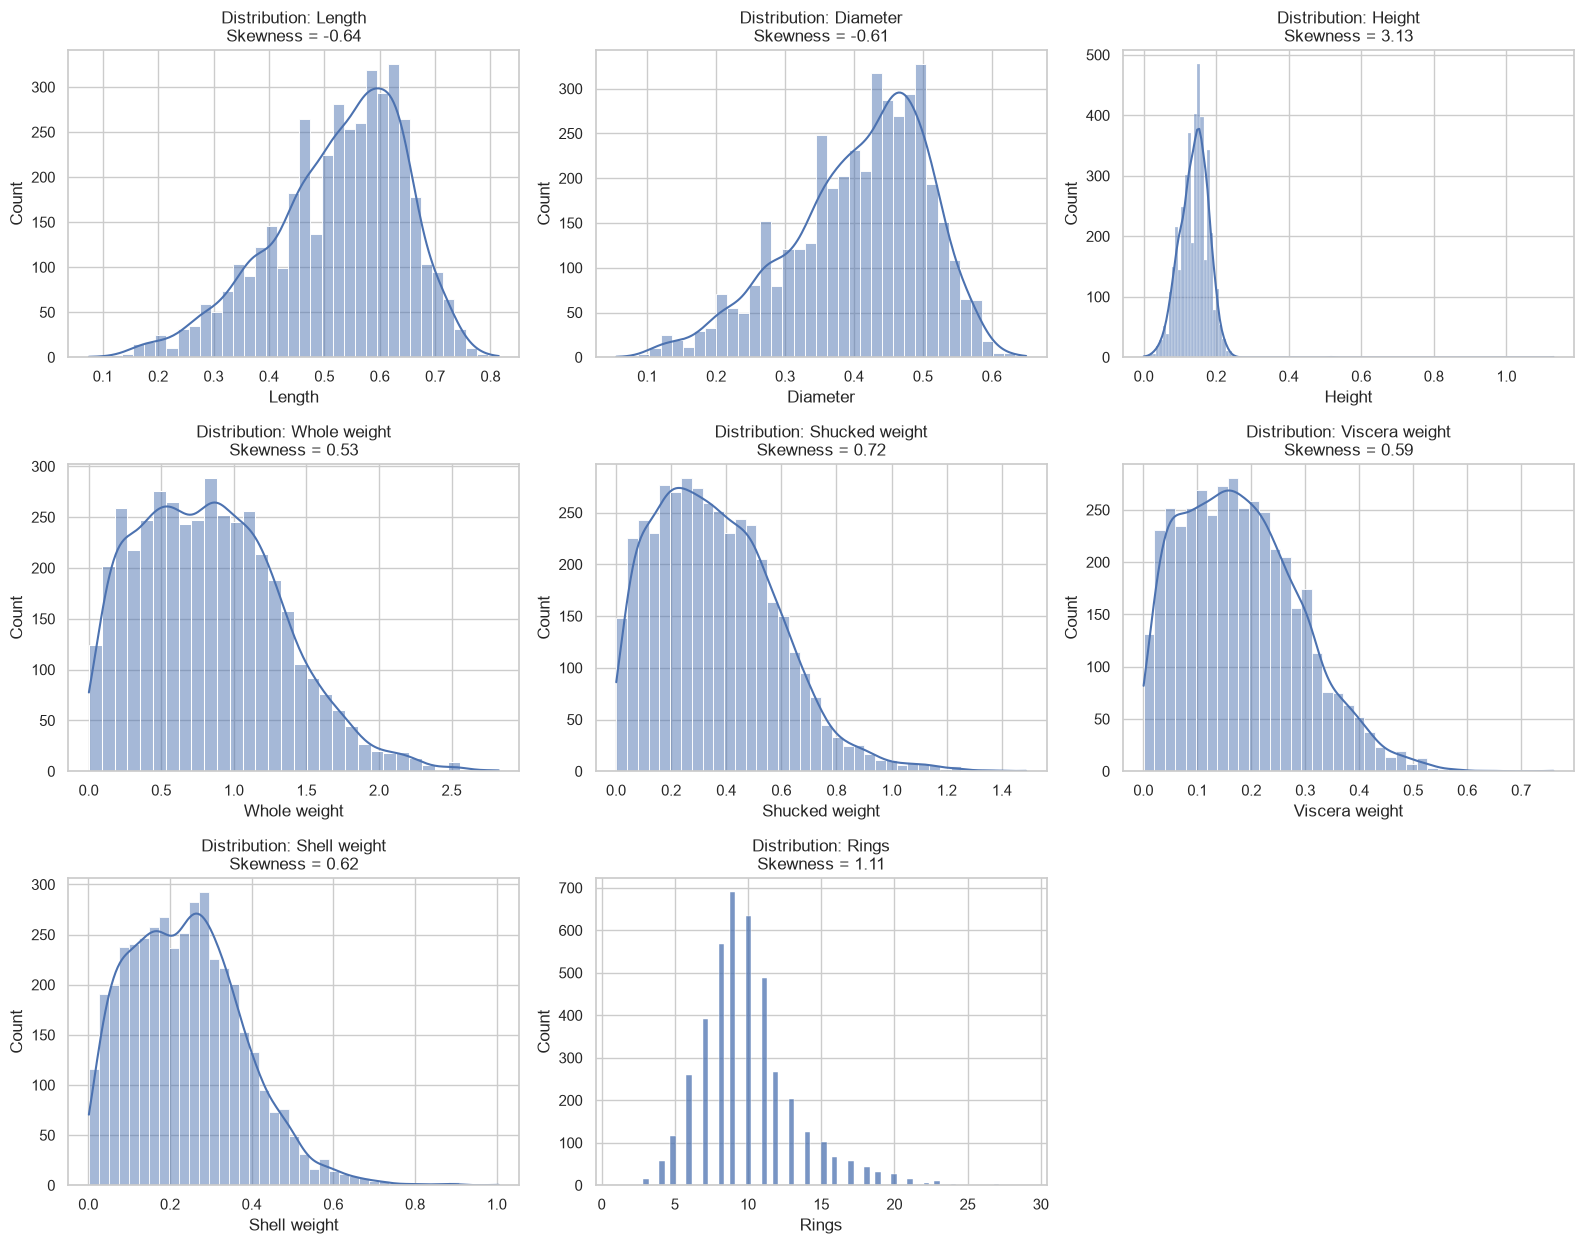

In [5]:
ncols = 3
nrows = int(np.ceil(len(NUMERIC_COLUMNS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.2 * nrows))
axes = np.asarray(axes).reshape(-1)

for ax, col in zip(axes, NUMERIC_COLUMNS):
    sns.histplot(data=df, x=col, kde=(col != TARGET), ax=ax, bins="auto")
    ax.set_title(f"Distribution: {col}\nSkewness = {df[col].skew():.2f}")
    ax.set_xlabel(col)

for ax in axes[len(NUMERIC_COLUMNS):]:
    ax.remove()

plt.tight_layout()
plt.show()


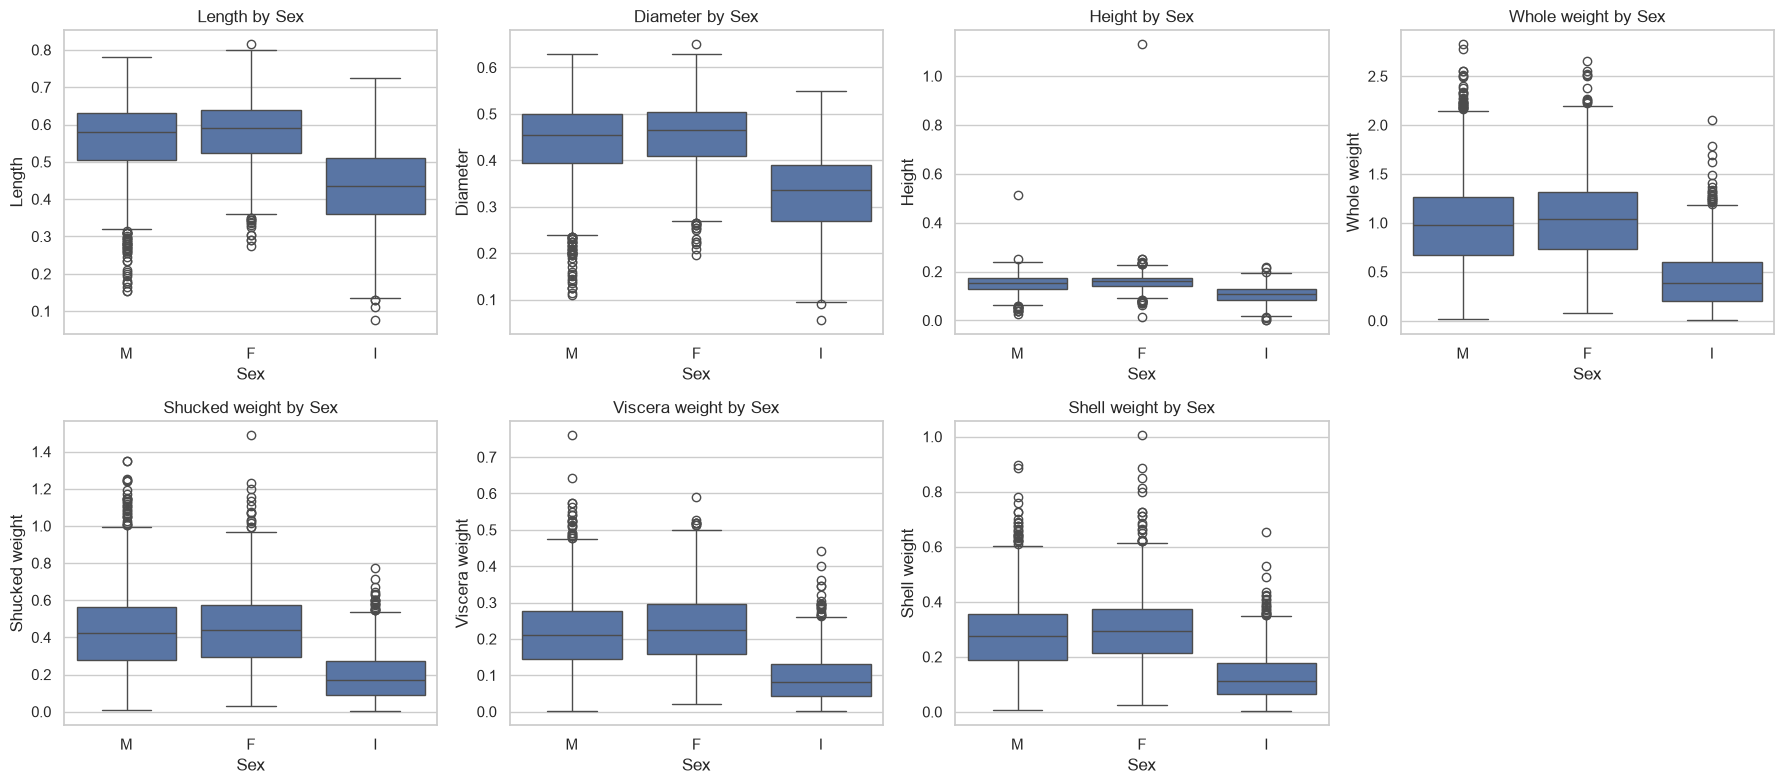

Length               Diameter               Height               Whole weight               Shucked weight                \
      mean median    std     mean median    std   mean median    std         mean median    std           mean median    std   
Sex                                                                                                                            
F    0.579  0.590  0.086    0.455  0.465  0.071  0.158  0.160  0.040        1.047  1.038  0.430          0.446  0.440  0.199   
I    0.428  0.435  0.109    0.326  0.335  0.088  0.108  0.110  0.032        0.431  0.384  0.286          0.191  0.170  0.128   
M    0.561  0.580  0.103    0.439  0.455  0.084  0.151  0.155  0.035        0.991  0.976  0.471          0.433  0.422  0.223   

    Viscera weight               Shell weight                 Rings                
              mean median    std         mean median    std    mean median    std  
Sex                                                                                
F            0.231  0.224  0.098        0.302  0.295  0.126  11.129   10.0  3.104  
I            0.092  0.080  0.063        0.128  0.113  0.085   7.890    8.0  2.512  
M            0.216  0.210  0.105        0.282  0.276  0.131  10.705   10.0  3.026

In [6]:
# Compare distributions by Sex to see whether group differences may matter.
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for ax, col in zip(axes, PREDICTOR_NUMERIC):
    sns.boxplot(data=df, x="Sex", y=col, ax=ax)
    ax.set_title(f"{col} by Sex")
for ax in axes[len(PREDICTOR_NUMERIC):]:
    ax.remove()
plt.tight_layout()
plt.show()

display(df.groupby("Sex")[NUMERIC_COLUMNS].agg(["mean", "median", "std"]).round(3))


## 5. Are any features capped or bounded?

In [7]:
cap_report = pd.DataFrame(index=NUMERIC_COLUMNS)
cap_report["min"] = df[NUMERIC_COLUMNS].min()
cap_report["max"] = df[NUMERIC_COLUMNS].max()
cap_report["count_at_min"] = [(df[c] == df[c].min()).sum() for c in NUMERIC_COLUMNS]
cap_report["pct_at_min"] = [100 * (df[c] == df[c].min()).mean() for c in NUMERIC_COLUMNS]
cap_report["count_at_max"] = [(df[c] == df[c].max()).sum() for c in NUMERIC_COLUMNS]
cap_report["pct_at_max"] = [100 * (df[c] == df[c].max()).mean() for c in NUMERIC_COLUMNS]
cap_report["n_unique"] = df[NUMERIC_COLUMNS].nunique()
cap_report["unique_pct"] = 100 * cap_report["n_unique"] / len(df)
display(cap_report.round(3))


,min,max,count_at_min,pct_at_min,count_at_max,pct_at_max,n_unique,unique_pct
Length,0.075,0.815,1,0.024,1,0.024,134,3.208
Diameter,0.055,0.650,1,0.024,1,0.024,111,2.657
Height,0.000,1.130,2,0.048,1,0.024,51,1.221
Whole weight,0.002,2.826,1,0.024,1,0.024,2429,58.152
Shucked weight,0.001,1.488,1,0.024,1,0.024,1515,36.270
Viscera weight,0.000,0.760,2,0.048,1,0.024,880,21.068
Shell weight,0.002,1.005,1,0.024,1,0.024,926,22.169
Rings,1.000,29.000,1,0.024,1,0.024,28,0.670


### Observations
- Most numerical features have one observation at min and max, `Height` having two zero minimums
- Based on the minute number of extreme values, it is reasonable to say that none of features in the dataset are capped

## 6. Covariance, Pearson correlation, and Spearman correlation

These calculations use numeric columns, including `Rings`. `Sex` is excluded because it is categorical.

In [8]:
numeric_data = df[NUMERIC_COLUMNS].copy()

covariance_matrix = numeric_data.cov()
pearson_corr = numeric_data.corr(method="pearson")
spearman_corr = numeric_data.corr(method="spearman")

print("Covariance matrix:")
display(covariance_matrix.round(4))

print("Pearson correlation matrix:")
display(pearson_corr.round(3))

print("Spearman correlation matrix:")
display(spearman_corr.round(3))


Covariance matrix:


,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
Length,0.0144,0.0118,0.0042,0.0545,0.0239,0.0119,0.0150,0.2156
Diameter,0.0118,0.0098,0.0035,0.0450,0.0197,0.0098,0.0125,0.1839
Height,0.0042,0.0035,0.0017,0.0168,0.0072,0.0037,0.0048,0.0752
Whole weight,0.0545,0.0450,0.0168,0.2405,0.1055,0.0519,0.0652,0.8544
Shucked weight,0.0239,0.0197,0.0072,0.1055,0.0493,0.0227,0.0273,0.3012
Viscera weight,0.0119,0.0098,0.0037,0.0519,0.0227,0.0120,0.0138,0.1781
Shell weight,0.0150,0.0125,0.0048,0.0652,0.0273,0.0138,0.0194,0.2817
Rings,0.2156,0.1839,0.0752,0.8544,0.3012,0.1781,0.2817,10.3953


Pearson correlation matrix:


,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
Length,1.000,0.987,0.828,0.925,0.898,0.903,0.898,0.557
Diameter,0.987,1.000,0.834,0.925,0.893,0.900,0.905,0.575
Height,0.828,0.834,1.000,0.819,0.775,0.798,0.817,0.557
Whole weight,0.925,0.925,0.819,1.000,0.969,0.966,0.955,0.540
Shucked weight,0.898,0.893,0.775,0.969,1.000,0.932,0.883,0.421
Viscera weight,0.903,0.900,0.798,0.966,0.932,1.000,0.908,0.504
Shell weight,0.898,0.905,0.817,0.955,0.883,0.908,1.000,0.628
Rings,0.557,0.575,0.557,0.540,0.421,0.504,0.628,1.000


Spearman correlation matrix:


,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
Length,1.000,0.983,0.888,0.973,0.957,0.953,0.948,0.604
Diameter,0.983,1.000,0.896,0.971,0.950,0.948,0.954,0.623
Height,0.888,0.896,1.000,0.916,0.874,0.901,0.921,0.658
Whole weight,0.973,0.971,0.916,1.000,0.977,0.975,0.969,0.631
Shucked weight,0.957,0.950,0.874,0.977,1.000,0.948,0.918,0.539
Viscera weight,0.953,0.948,0.901,0.975,0.948,1.000,0.938,0.614
Shell weight,0.948,0.954,0.921,0.969,0.918,0.938,1.000,0.692
Rings,0.604,0.623,0.658,0.631,0.539,0.614,0.692,1.000


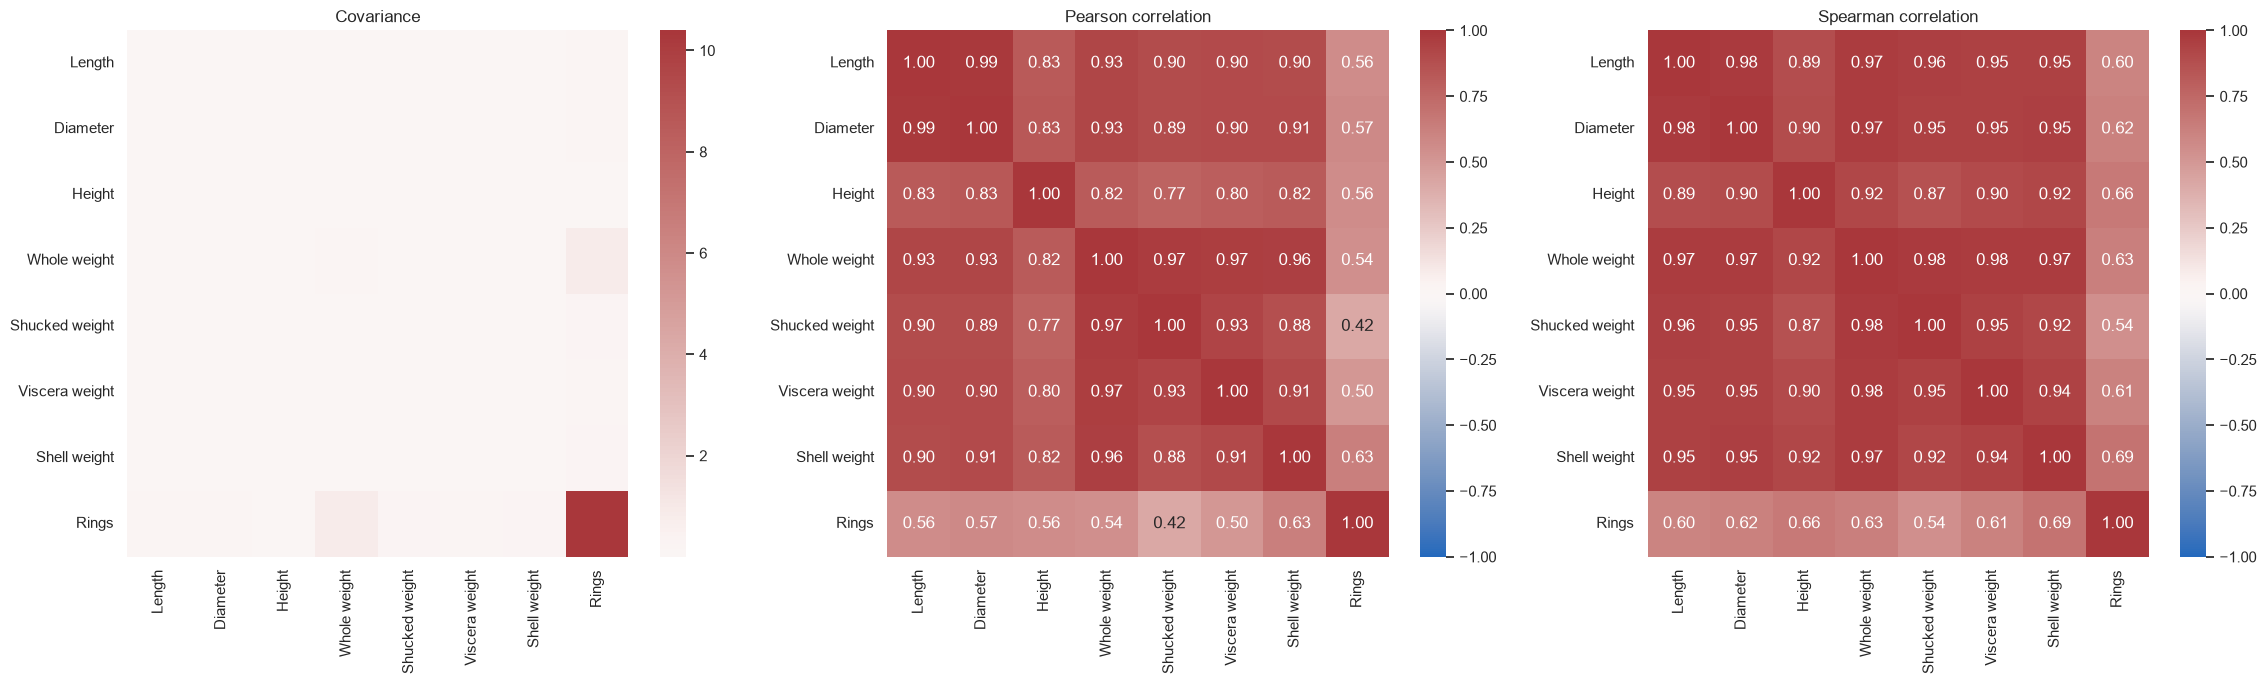

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(23, 7))
sns.heatmap(covariance_matrix, cmap="vlag", center=0, ax=axes[0])
axes[0].set_title("Covariance")
sns.heatmap(pearson_corr, cmap="vlag", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("Pearson correlation")
sns.heatmap(spearman_corr, cmap="vlag", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=axes[2])
axes[2].set_title("Spearman correlation")
plt.tight_layout()
plt.show()


In [10]:
# Rank predictor pairs by absolute correlation; the diagonal and duplicate pairs are excluded.
def upper_triangle_pairs(corr_matrix):
    pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
    return pairs.rename("correlation").to_frame().assign(
        absolute_correlation=lambda x: x["correlation"].abs()
    ).sort_values("absolute_correlation", ascending=False)

print("Strongest Pearson-correlated pairs:")
display(upper_triangle_pairs(pearson_corr).head(15).round(3))

print("Strongest Spearman-correlated pairs:")
display(upper_triangle_pairs(spearman_corr).head(15).round(3))

print("Differences between Spearman and Pearson correlations:")
corr_difference = (spearman_corr - pearson_corr).stack().rename("spearman_minus_pearson").to_frame()
corr_difference = corr_difference.loc[corr_difference.index.get_level_values(0) < corr_difference.index.get_level_values(1)]
corr_difference["absolute_difference"] = corr_difference["spearman_minus_pearson"].abs()
display(corr_difference.sort_values("absolute_difference", ascending=False).head(15).round(3))


Strongest Pearson-correlated pairs:


correlation  absolute_correlation
Length         Diameter              0.987                 0.987
Whole weight   Shucked weight        0.969                 0.969
               Viscera weight        0.966                 0.966
               Shell weight          0.955                 0.955
Shucked weight Viscera weight        0.932                 0.932
Diameter       Whole weight          0.925                 0.925
Length         Whole weight          0.925                 0.925
Viscera weight Shell weight          0.908                 0.908
Diameter       Shell weight          0.905                 0.905
Length         Viscera weight        0.903                 0.903
Diameter       Viscera weight        0.900                 0.900
Length         Shucked weight        0.898                 0.898
               Shell weight          0.898                 0.898
Diameter       Shucked weight        0.893                 0.893
Shucked weight Shell weight          0.883                 0.883

Strongest Spearman-correlated pairs:


correlation  absolute_correlation
Length         Diameter              0.983                 0.983
Whole weight   Shucked weight        0.977                 0.977
               Viscera weight        0.975                 0.975
Length         Whole weight          0.973                 0.973
Diameter       Whole weight          0.971                 0.971
Whole weight   Shell weight          0.969                 0.969
Length         Shucked weight        0.957                 0.957
Diameter       Shell weight          0.954                 0.954
Length         Viscera weight        0.953                 0.953
Diameter       Shucked weight        0.950                 0.950
               Viscera weight        0.948                 0.948
Length         Shell weight          0.948                 0.948
Shucked weight Viscera weight        0.948                 0.948
Viscera weight Shell weight          0.938                 0.938
Height         Shell weight          0.921                 0.921

Differences between Spearman and Pearson correlations:


spearman_minus_pearson  absolute_difference
Rings    Shucked weight                   0.119                0.119
         Viscera weight                   0.111                0.111
Height   Shell weight                     0.104                0.104
         Viscera weight                   0.102                0.102
         Rings                            0.100                0.100
         Shucked weight                   0.099                0.099
         Whole weight                     0.097                0.097
Rings    Whole weight                     0.090                0.090
         Shell weight                     0.065                0.065
Diameter Height                           0.062                0.062
Height   Length                           0.061                0.061
Length   Shucked weight                   0.059                0.059
Diameter Shucked weight                   0.057                0.057
Length   Shell weight                     0.050                0.050
         Viscera weight                   0.050                0.050

### Important Findings
- `Length` and `Diameter` have a Pearson correlation of 0.987
- `Whole weight` and `Shuckled Weight` have a Pearson correlation of 0.969
- `Whole weight` and `Viscera Weight` have a Pearson correlation of 0.966
- `Whole weight` and `Shell Weight` have a Pearson correlation of 0.955
- `Diameter` and `Whole weight` have a Pearson correlation of 0.925
- `Length` and `Whole weight` have a Pearson correlation of 0.925
- `Shell weight` has highest correlation with `Rings`(Pearson correlation of 0.628)
-  Spearman correlations were often higher than Pearson correlations
-  Covariance contained positve values for numeric features 

  This makes phsyical sense, naturally a larger abalone would be heavier. This amount of redunancy may prove to be a problem, but for now all of these features will stay. Set aside a model that has the less correlated features and compare it to a model with all features to prove if that is the case  

## 7. Pairwise plots to inspect relationships

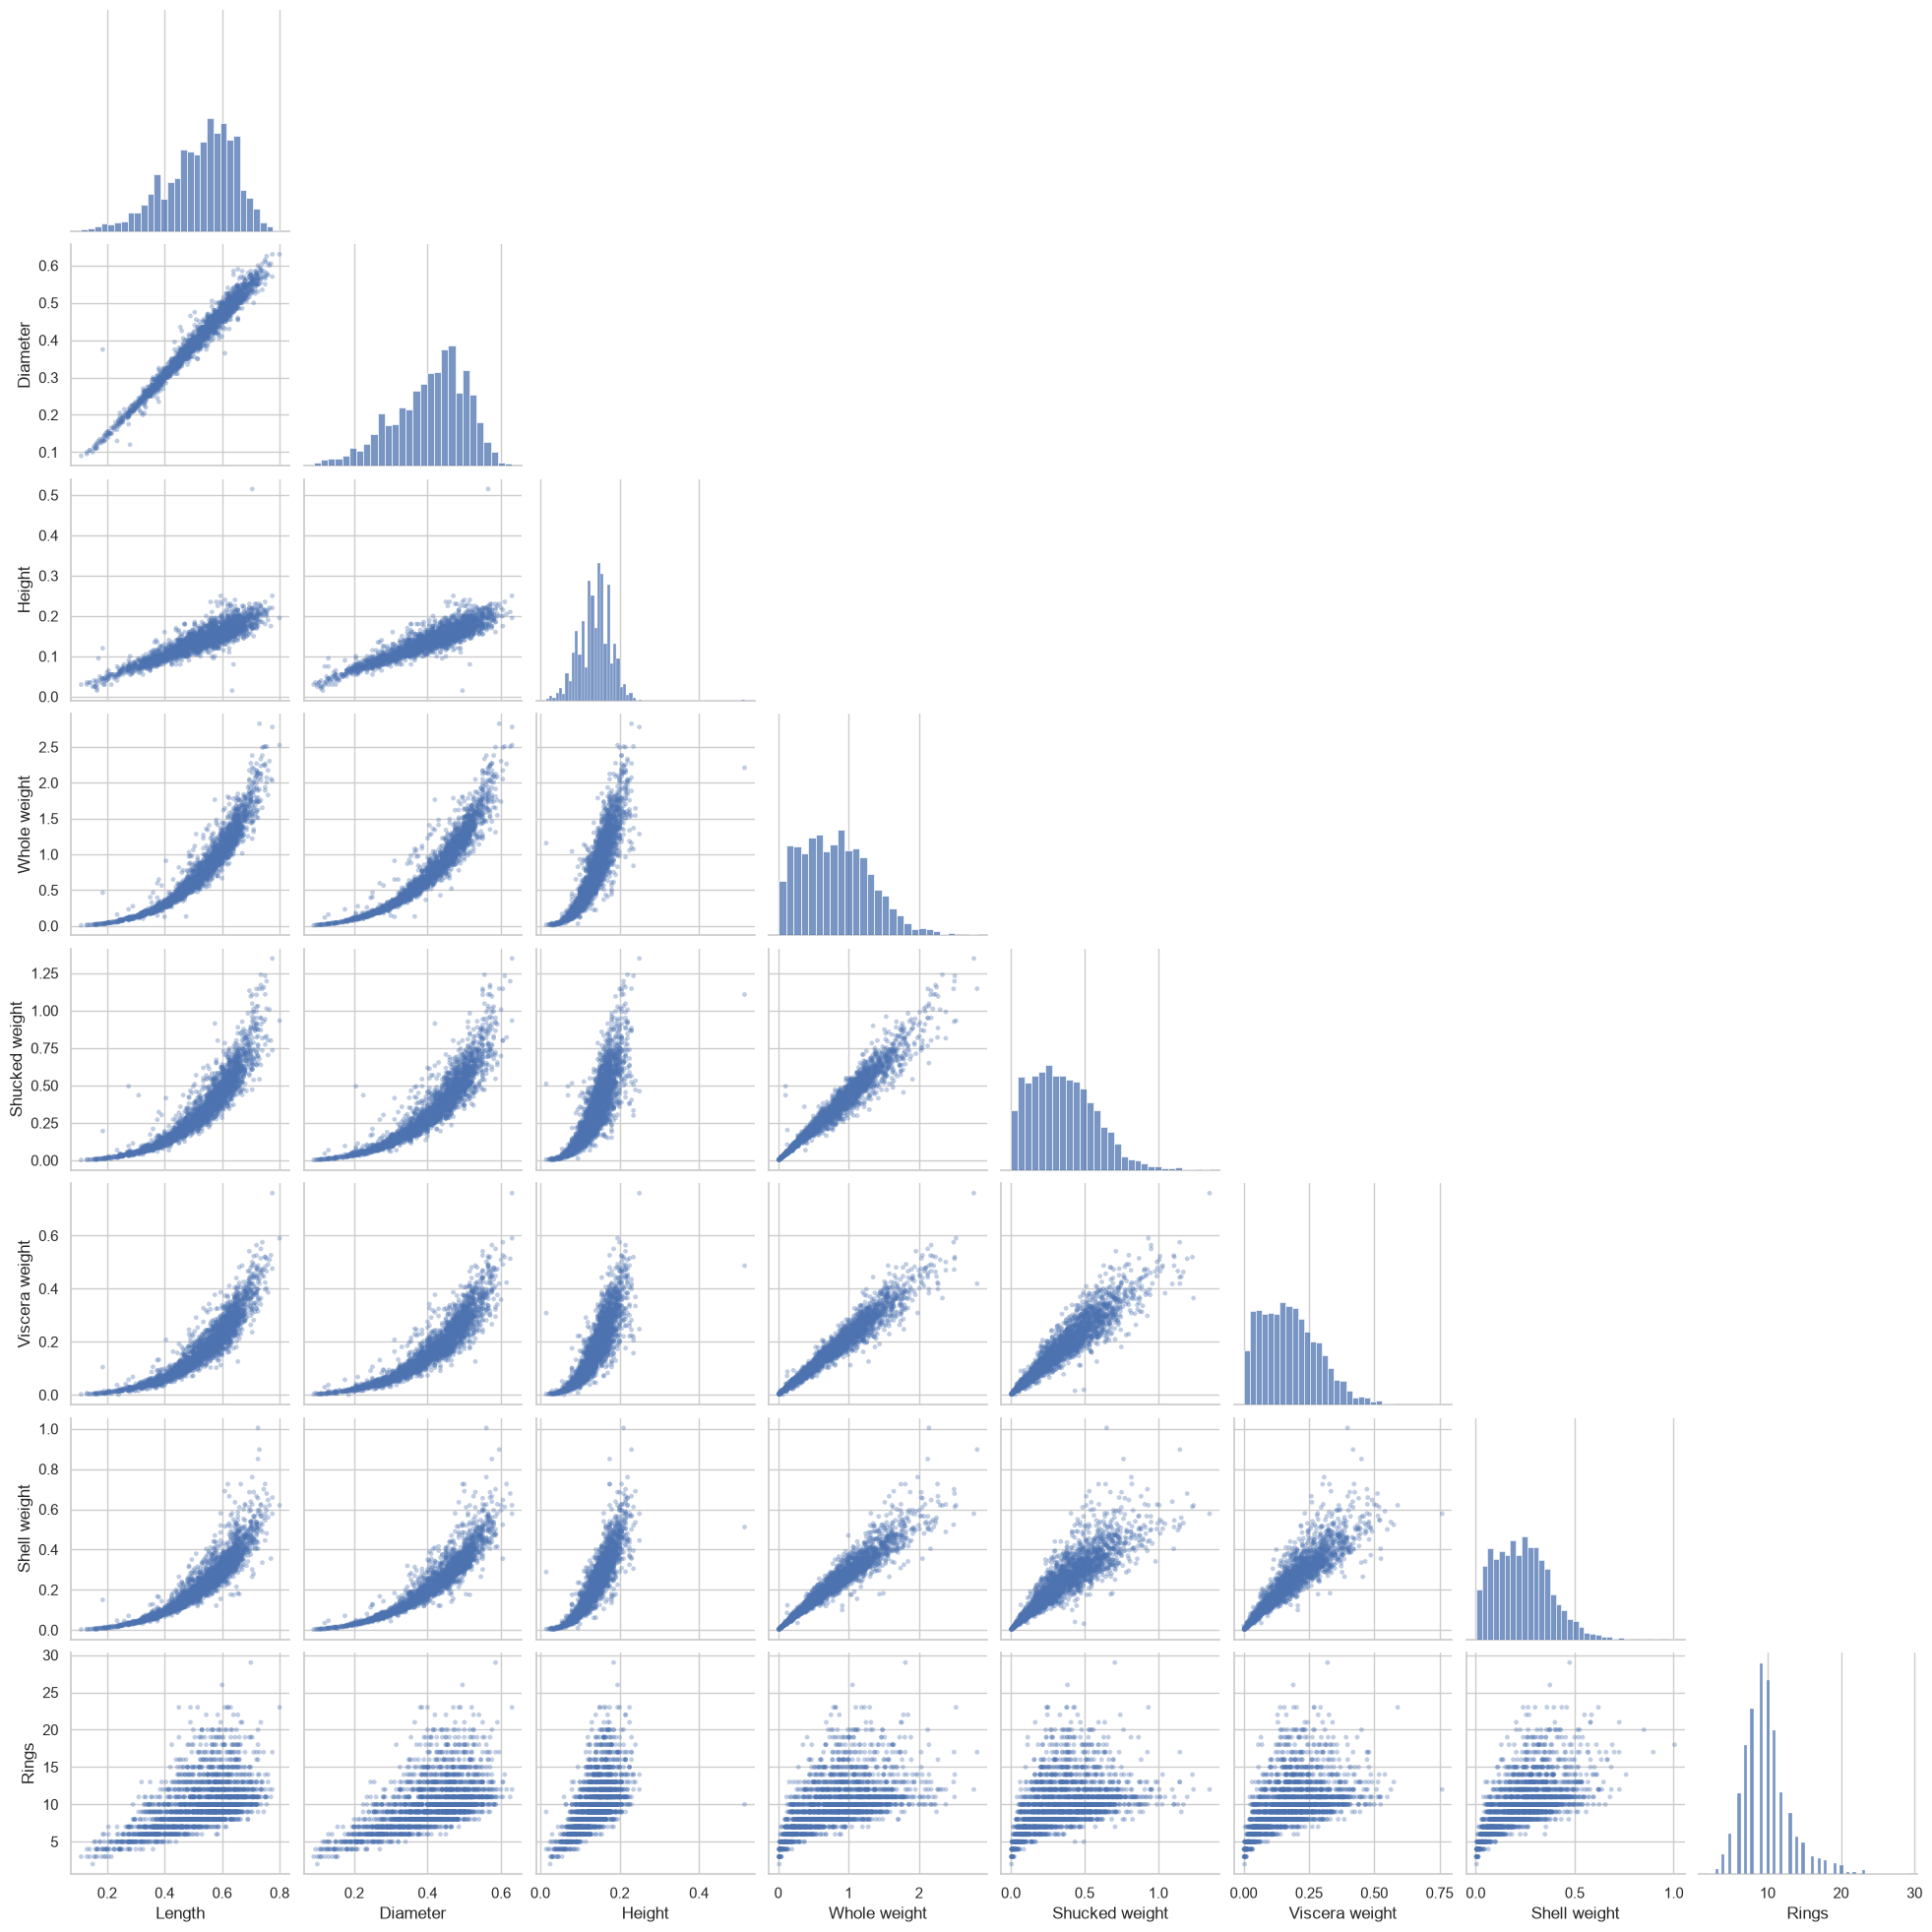

In [11]:
plot_df = df.sample(min(len(df), 2500), random_state=RANDOM_STATE)
sns.pairplot(
    plot_df[["Length", "Diameter", "Height", "Whole weight", "Shucked weight",
             "Viscera weight", "Shell weight", "Rings"]],
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.35, "s": 12, "edgecolor": "none"}
)
plt.show()


## 8. Outlier detection 

These are only potential outliers. The table reports low/high outliers separately, along with unique affected rows.

In [12]:
outlier_rows = {}
outlier_records = []

for col in NUMERIC_COLUMNS:
    series = df[col].dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    low_mask = df[col] < lower
    high_mask = df[col] > upper
    mask = low_mask | high_mask
    outlier_rows[col] = mask
    outlier_records.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_fence": lower,
        "upper_fence": upper,
        "low_outliers": int(low_mask.sum()),
        "high_outliers": int(high_mask.sum()),
        "total_outliers": int(mask.sum()),
        "percent_outliers": 100 * mask.sum() / df[col].notna().sum(),
    })

outlier_summary = pd.DataFrame(outlier_records).set_index("feature")
display(outlier_summary.round(4))

any_outlier_mask = pd.DataFrame(outlier_rows).any(axis=1)
print(f"Rows flagged in at least one numeric feature: {any_outlier_mask.sum():,} "
      f"({100 * any_outlier_mask.mean():.2f}% of rows)")


,Q1,Q3,IQR,lower_fence,upper_fence,low_outliers,high_outliers,total_outliers,percent_outliers
feature,,,,,,,,,
Length,0.4500,0.615,0.1650,0.2025,0.8625,49,0,49,1.1731
Diameter,0.3500,0.480,0.1300,0.1550,0.6750,59,0,59,1.4125
Height,0.1150,0.165,0.0500,0.0400,0.2400,24,5,29,0.6943
Whole weight,0.4415,1.153,0.7115,-0.6258,2.2202,0,30,30,0.7182
Shucked weight,0.1860,0.502,0.3160,-0.2880,0.9760,0,48,48,1.1492
Viscera weight,0.0935,0.253,0.1595,-0.1458,0.4922,0,26,26,0.6225
Shell weight,0.1300,0.329,0.1990,-0.1685,0.6275,0,35,35,0.8379
Rings,8.0000,11.000,3.0000,3.5000,15.5000,17,261,278,6.6555


Rows flagged in at least one numeric feature: 396 (9.48% of rows)


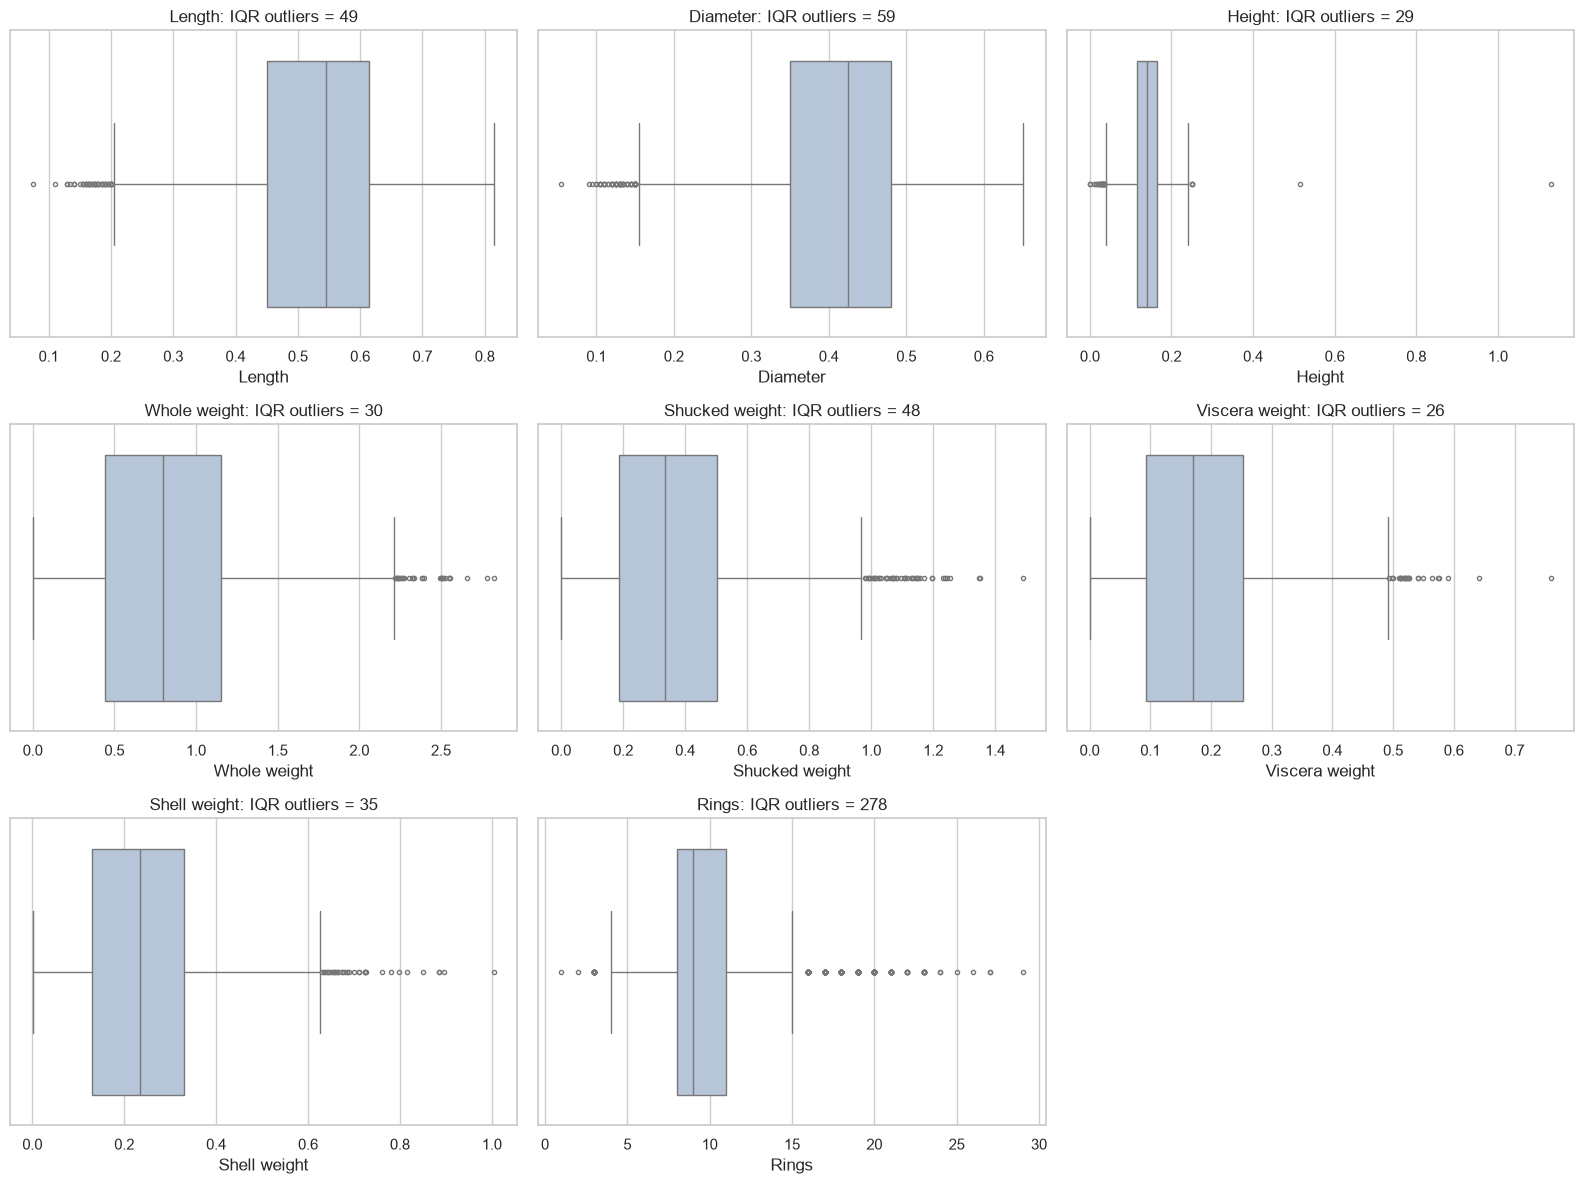

In [13]:
# Boxplots to make IQR-flagged extremes visible
ncols = 3
nrows = int(np.ceil(len(NUMERIC_COLUMNS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.asarray(axes).reshape(-1)

for ax, col in zip(axes, NUMERIC_COLUMNS):
    sns.boxplot(x=df[col], ax=ax, color="lightsteelblue", fliersize=3)
    ax.set_title(f"{col}: IQR outliers = {int(outlier_rows[col].sum())}")
    ax.set_xlabel(col)

for ax in axes[len(NUMERIC_COLUMNS):]:
    ax.remove()
plt.tight_layout()
plt.show()


In [14]:
# Lists the most extreme flagged values per feature
extreme_examples = []
for col in NUMERIC_COLUMNS:
    mask = outlier_rows[col]
    if mask.any():
        temp = df.loc[mask, [col]].copy()
        temp["row_index"] = temp.index
        temp["feature"] = col
        temp["side"] = np.where(temp[col] < outlier_summary.loc[col, "lower_fence"], "low", "high")
        temp["distance_outside_fence"] = np.where(
            temp[col] < outlier_summary.loc[col, "lower_fence"],
            outlier_summary.loc[col, "lower_fence"] - temp[col],
            temp[col] - outlier_summary.loc[col, "upper_fence"]
        )
        extreme_examples.append(temp[["row_index", "feature", col, "side", "distance_outside_fence"]])

if extreme_examples:
    extreme_examples = pd.concat(extreme_examples, ignore_index=True)
    display(extreme_examples.sort_values("distance_outside_fence", ascending=False).groupby("feature").head(10))
else:
    print("No IQR outliers were detected.")


,row_index,feature,Length,side,distance_outside_fence,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
358,480,Rings,NaN,high,13.500,NaN,NaN,NaN,NaN,NaN,NaN,29.0
436,2209,Rings,NaN,high,11.500,NaN,NaN,NaN,NaN,NaN,NaN,27.0
420,2108,Rings,NaN,high,11.500,NaN,NaN,NaN,NaN,NaN,NaN,27.0
310,294,Rings,NaN,high,10.500,NaN,NaN,NaN,NaN,NaN,NaN,26.0
432,2201,Rings,NaN,high,9.500,NaN,NaN,NaN,NaN,NaN,NaN,25.0
...,...,...,...,...,...,...,...,...,...,...,...,...
117,1174,Height,NaN,low,0.025,NaN,0.015,NaN,NaN,NaN,NaN,NaN
126,2169,Height,NaN,low,0.025,NaN,0.015,NaN,NaN,NaN,NaN,NaN
135,3902,Height,NaN,low,0.020,NaN,0.020,NaN,NaN,NaN,NaN,NaN
113,694,Height,NaN,low,0.020,NaN,0.020,NaN,NaN,NaN,NaN,NaN


### Outlier decision

There were 396 rows that had an outlier, making up about 9.48% of the total data. Most occured in the `Rings` feature, but as `Rings` is discrete, it is likely that some abalones were genuinely older. As such, they shall not be removed. Later, a sensitivity analysis might be necessary, so compare model performance with and without justified exclusions (namely the two instances of zero height). Of course, don't use the test set to choose an outlier policy. Side Note: For tree-based models, valid extreme values are often less problematic than for linear models, but they can still influence the learned splits or loss.

## 9. Does scaling need to be applied?

It depends on the model. It is usually unnecessary for decision trees, random forests, and standard gradient-boosted trees. But, it is often important for linear models with regularization.

Use a scikit-learn `Pipeline`/`ColumnTransformer` so imputation, encoding, and scaling are fitted on training folds only as to prevent leakage. Use either `StandardScaler` as a default or `RobustScaler` if extreme values materially affect scale-sensitive models.

In [15]:
# Example preprocessing pipelines for a later train/test model comparison.
# This cell defines pipelines only
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_transform_standard = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
numeric_transform_robust = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
categorical_transform = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_standard = ColumnTransformer(transformers=[
    ("numeric", numeric_transform_standard, PREDICTOR_NUMERIC),
    ("categorical", categorical_transform, CATEGORICAL_FEATURES)
])

preprocessor_robust = ColumnTransformer(transformers=[
    ("numeric", numeric_transform_robust, PREDICTOR_NUMERIC),
    ("categorical", categorical_transform, CATEGORICAL_FEATURES)
])

print("Defined StandardScaler and RobustScaler preprocessing pipelines.")


Defined StandardScaler and RobustScaler preprocessing pipelines.


## 10. Initial feature-selection notes

While correlations between some numerical features were high, it is best to retain as much data as possible with the initial models. Therefore, all features shall remain for the time being. It would be in our best interest to make a separate model with features that are less correlated and compare with a model with the full 8 features. The `Sex` feature will also need to be one-hot encoded to integrate it into the model.

## 11. Summary

- No missing values
- 2 zero values in `Height` and one max value of 1.13
- `Rings` is the target feature, abalones have an age of approximately `Rings` + 1.5 years
- Height and Rings are right-skewed
- No features are capped
- Features regarding size and weight are highly correlated, but all 8 features shall remain for now
- `Shell weight` appears to be the most correlated to `Rings`
- 396 rows had at least one outlier, but that only comprises of 9.48% of the data, so they will not be removed
- Only suspicious values were the two zeros and max of 1.13 in `Height`
- The two zeroes are up for consideration to be removed, but will remain for now
- No scaling will be required for tree-based models, but with the logistic regression models, it would be beneficial to use `StandardScaler` or `RobustScaler`